### Imputation Techniques 
#### Petrophysical Data Imputation with AI

#### This comprehensive tutorial shows how AI-based imputation methods can handle missing petrophysical data while preserving important relationships between variables. The key is choosing the right method based on your data characteristics and project requirements.

#### Keith R. Holdaway FGS

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings('ignore')

# Set up plotting style
plt.style.use('seaborn-v0_8')
print("=== Petrophysical Data Imputation Tutorial ===\n")

=== Petrophysical Data Imputation Tutorial ===



#### 1. Understanding Imputation
What is Imputation?
Imputation is the process of replacing missing data with substituted values. In petrophysics, we often deal with incomplete well logs due to:

Tool malfunctions

Bad hole conditions

Different logging runs

Data acquisition issues

In [2]:
# Let's create a synthetic petrophysical dataset with missing values
np.random.seed(42)

# Create synthetic well log data
n_samples = 200
depth = np.arange(n_samples)

# Synthetic petrophysical parameters
gr = 20 + 80 * np.random.beta(2, 5, n_samples)  # Gamma Ray (API)
rhob = 2.0 + 0.8 * np.random.beta(2, 2, n_samples)  # Bulk Density (g/cc)
nphi = 0.05 + 0.25 * np.random.beta(2, 3, n_samples)  # Neutron Porosity (v/v)
dt = 40 + 80 * np.random.beta(3, 2, n_samples)  # Sonic (μs/ft)
resistivity = 0.5 + 100 * np.random.exponential(0.3, n_samples)  # Resistivity (ohm-m)

# Create DataFrame
df = pd.DataFrame({
    'DEPTH': depth,
    'GR': gr,
    'RHOB': rhob,
    'NPHI': nphi,
    'DT': dt,
    'RESISTIVITY': resistivity
})

print("Original Complete Dataset:")
print(df.head())
print(f"\nDataset shape: {df.shape}")

Original Complete Dataset:
   DEPTH         GR      RHOB      NPHI          DT  RESISTIVITY
0      0  48.294133  2.530519  0.094299   65.285342    76.550518
1      1  39.884645  2.643386  0.189437  108.542796     1.726507
2      2  53.276727  2.191804  0.162343   64.956446    10.836502
3      3  32.797406  2.097208  0.182877   88.477504     7.478433
4      4  64.022646  2.025750  0.146037  108.675745     8.660036

Dataset shape: (200, 6)


#### 2. Introducing Missing Data
Let's artificially create missing values to simulate real-world scenarios:

In [3]:
# Function to introduce missing values
def introduce_missing_data(df, missing_percentage=0.2):
    df_missing = df.copy()
    n_missing = int(len(df) * missing_percentage)
    
    # Randomly select indices to make missing for each column (except DEPTH)
    for col in ['GR', 'RHOB', 'NPHI', 'DT', 'RESISTIVITY']:
        missing_indices = np.random.choice(len(df), n_missing, replace=False)
        df_missing.loc[missing_indices, col] = np.nan
    
    return df_missing

# Create dataset with missing values
df_missing = introduce_missing_data(df, missing_percentage=0.15)

print("\nDataset with Missing Values:")
print(df_missing.head())
print(f"\nMissing values per column:")
print(df_missing.isnull().sum())


Dataset with Missing Values:
   DEPTH         GR      RHOB      NPHI          DT  RESISTIVITY
0      0        NaN  2.530519  0.094299   65.285342    76.550518
1      1  39.884645  2.643386       NaN  108.542796     1.726507
2      2  53.276727       NaN  0.162343   64.956446    10.836502
3      3  32.797406  2.097208  0.182877   88.477504          NaN
4      4  64.022646  2.025750  0.146037         NaN          NaN

Missing values per column:
DEPTH           0
GR             30
RHOB           30
NPHI           30
DT             30
RESISTIVITY    30
dtype: int64


#### 3. Visualizing Missing Data

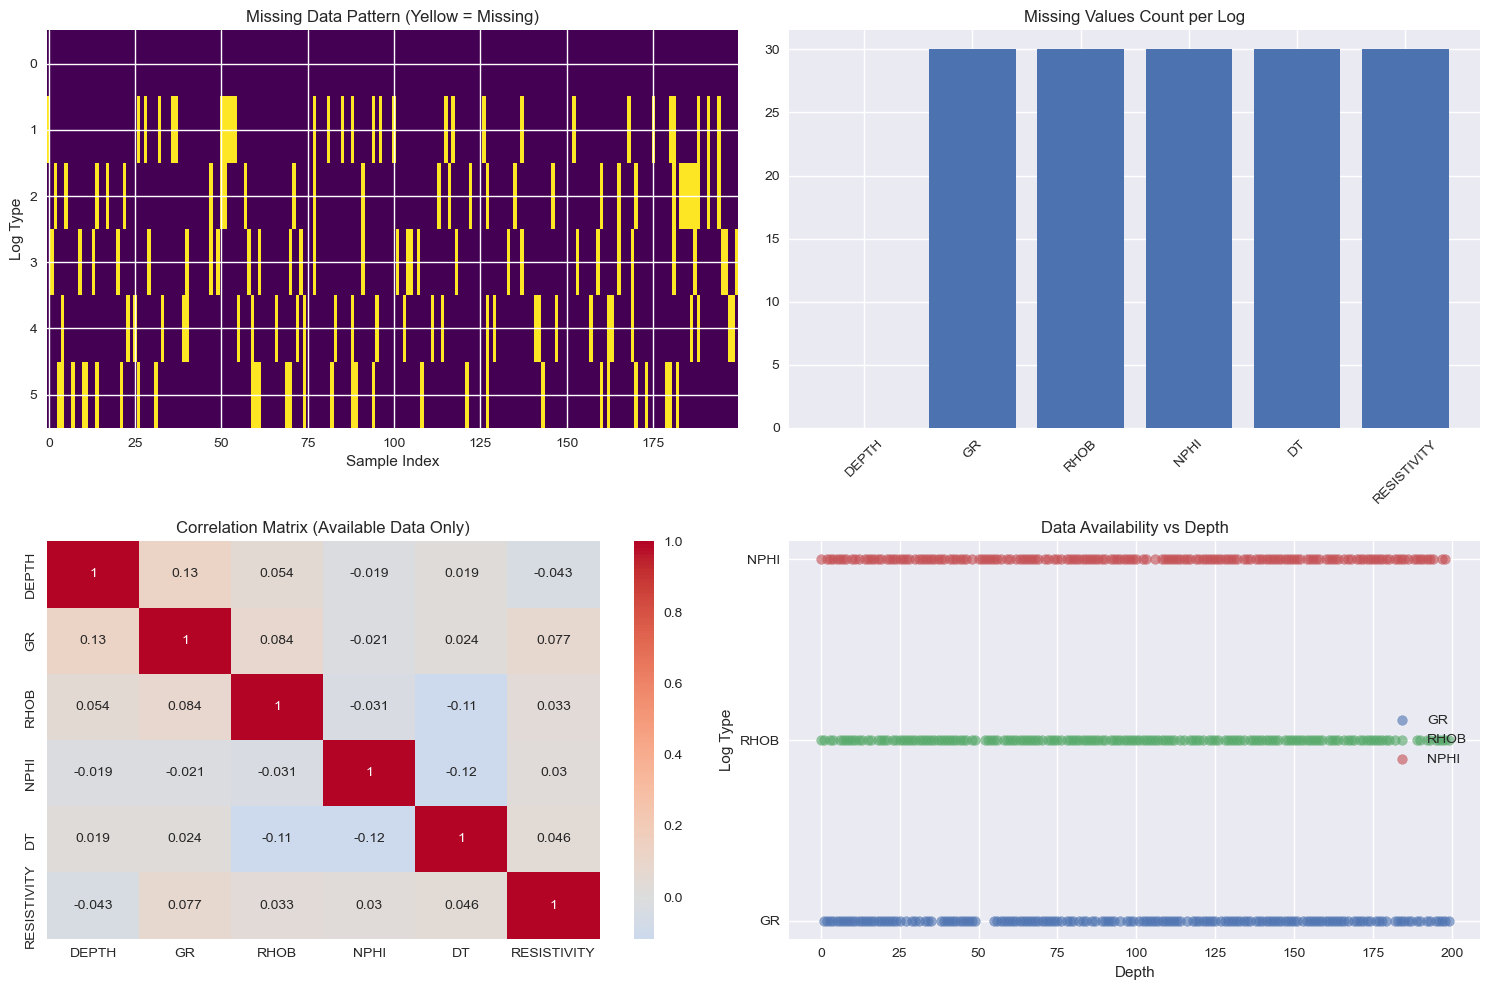

In [4]:
# Visualize missing data pattern
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Missing data matrix
axes[0,0].imshow(df_missing.isnull().T, aspect='auto', cmap='viridis', interpolation='none')
axes[0,0].set_title('Missing Data Pattern (Yellow = Missing)')
axes[0,0].set_xlabel('Sample Index')
axes[0,0].set_ylabel('Log Type')

# Missing data bar plot
missing_counts = df_missing.isnull().sum()
axes[0,1].bar(missing_counts.index, missing_counts.values)
axes[0,1].set_title('Missing Values Count per Log')
axes[0,1].tick_params(axis='x', rotation=45)

# Correlation matrix of available data
corr_matrix = df_missing.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, ax=axes[1,0])
axes[1,0].set_title('Correlation Matrix (Available Data Only)')

# Depth plot showing missing intervals
for col in ['GR', 'RHOB', 'NPHI']:
    available_data = df_missing[col].notnull()
    axes[1,1].scatter(df_missing.loc[available_data, 'DEPTH'], 
                     [col] * available_data.sum(), alpha=0.6, label=col)
axes[1,1].set_xlabel('Depth')
axes[1,1].set_ylabel('Log Type')
axes[1,1].set_title('Data Availability vs Depth')
axes[1,1].legend()

plt.tight_layout()
plt.show()

#### 4. Basic Imputation Techniques
4.1 Mean/Median Imputation

In [5]:
print("\n=== 1. MEAN/MEDIAN IMPUTATION ===")
print("Simple method replacing missing values with column mean or median")
print("Best for: Data with normal distribution, minimal outliers")

# Mean imputation
mean_imputer = SimpleImputer(strategy='mean')
df_mean = pd.DataFrame(mean_imputer.fit_transform(df_missing[['GR', 'RHOB', 'NPHI', 'DT', 'RESISTIVITY']]),
                      columns=['GR', 'RHOB', 'NPHI', 'DT', 'RESISTIVITY'])
df_mean['DEPTH'] = df_missing['DEPTH']

# Median imputation (more robust to outliers)
median_imputer = SimpleImputer(strategy='median')
df_median = pd.DataFrame(median_imputer.fit_transform(df_missing[['GR', 'RHOB', 'NPHI', 'DT', 'RESISTIVITY']]),
                        columns=['GR', 'RHOB', 'NPHI', 'DT', 'RESISTIVITY'])
df_median['DEPTH'] = df_missing['DEPTH']

print(f"Original GR stats: Mean={df['GR'].mean():.2f}, Median={df['GR'].median():.2f}")
print(f"Mean imputed GR stats: Mean={df_mean['GR'].mean():.2f}, Median={df_mean['GR'].median():.2f}")


=== 1. MEAN/MEDIAN IMPUTATION ===
Simple method replacing missing values with column mean or median
Best for: Data with normal distribution, minimal outliers
Original GR stats: Mean=41.84, Median=40.30
Mean imputed GR stats: Mean=41.30, Median=41.30


4.2 Forward/Backward Fill (Depth-based)

In [6]:
print("\n=== 2. FORWARD/BACKWARD FILL ===")
print("Uses adjacent depth values to fill missing data")
print("Best for: Depth-series data with local continuity")

df_ffill = df_missing.ffill()  # Forward fill (use previous depth value)
df_bfill = df_missing.bfill()  # Backward fill (use next depth value)

# Combined approach: forward then backward fill
df_depth_fill = df_missing.ffill().bfill()

print("Example of depth-based filling:")
print("Original missing values at sample 5:")
print(df_missing.loc[4:6, ['DEPTH', 'GR', 'RHOB']])
print("\nAfter forward fill:")
print(df_ffill.loc[4:6, ['DEPTH', 'GR', 'RHOB']])


=== 2. FORWARD/BACKWARD FILL ===
Uses adjacent depth values to fill missing data
Best for: Depth-series data with local continuity
Example of depth-based filling:
Original missing values at sample 5:
   DEPTH         GR      RHOB
4      4  64.022646  2.025750
5      5  28.875623       NaN
6      6  60.791731  2.394596

After forward fill:
   DEPTH         GR      RHOB
4      4  64.022646  2.025750
5      5  28.875623  2.025750
6      6  60.791731  2.394596


#### 5. Advanced AI-based Imputation
5.1 K-Nearest Neighbors (KNN) Imputation

In [7]:
print("\n=== 3. K-NEAREST NEIGHBORS (KNN) IMPUTATION ===")
print("Finds similar samples based on available features")
print("Best for: Datasets with correlated features")

knn_imputer = KNNImputer(n_neighbors=5)
df_knn = pd.DataFrame(knn_imputer.fit_transform(df_missing[['GR', 'RHOB', 'NPHI', 'DT', 'RESISTIVITY']]),
                     columns=['GR', 'RHOB', 'NPHI', 'DT', 'RESISTIVITY'])
df_knn['DEPTH'] = df_missing['DEPTH']

print("KNN imputation uses patterns from similar depth intervals")


=== 3. K-NEAREST NEIGHBORS (KNN) IMPUTATION ===
Finds similar samples based on available features
Best for: Datasets with correlated features
KNN imputation uses patterns from similar depth intervals


5.2 Iterative Imputation (MICE)

In [8]:
print("\n=== 4. ITERATIVE IMPUTATION (MICE) ===")
print("Models each feature with missing values as a function of other features")
print("Best for: Complex datasets with multiple correlated variables")

iterative_imputer = IterativeImputer(estimator=RandomForestRegressor(n_estimators=100, random_state=42),
                                    max_iter=10, random_state=42)
df_iterative = pd.DataFrame(iterative_imputer.fit_transform(df_missing[['GR', 'RHOB', 'NPHI', 'DT', 'RESISTIVITY']]),
                           columns=['GR', 'RHOB', 'NPHI', 'DT', 'RESISTIVITY'])
df_iterative['DEPTH'] = df_missing['DEPTH']

print("Iterative imputation models relationships between variables")


=== 4. ITERATIVE IMPUTATION (MICE) ===
Models each feature with missing values as a function of other features
Best for: Complex datasets with multiple correlated variables
Iterative imputation models relationships between variables


#### 6. Comparison and Evaluation

In [9]:
# Let's evaluate the imputation methods
def evaluate_imputation(original_df, imputed_df, missing_mask):
    """Evaluate imputation quality using RMSE"""
    rmse_scores = {}
    for col in ['GR', 'RHOB', 'NPHI', 'DT', 'RESISTIVITY']:
        original_values = original_df[col].values[missing_mask[col]]
        imputed_values = imputed_df[col].values[missing_mask[col]]
        rmse = np.sqrt(mean_squared_error(original_values, imputed_values))
        rmse_scores[col] = rmse
    return rmse_scores

# Create missing value mask
missing_mask = {}
for col in ['GR', 'RHOB', 'NPHI', 'DT', 'RESISTIVITY']:
    missing_mask[col] = df_missing[col].isnull()

# Evaluate all methods
methods = {
    'Mean': df_mean,
    'Median': df_median,
    'Depth Fill': df_depth_fill,
    'KNN': df_knn,
    'Iterative': df_iterative
}

evaluation_results = {}
for method_name, imputed_df in methods.items():
    evaluation_results[method_name] = evaluate_imputation(df, imputed_df, missing_mask)

# Convert to DataFrame for easier plotting
eval_df = pd.DataFrame(evaluation_results)
print("\n=== IMPUTATION EVALUATION (RMSE) ===")
print("Lower values indicate better performance:")
print(eval_df.round(3))


=== IMPUTATION EVALUATION (RMSE) ===
Lower values indicate better performance:
               Mean  Median  Depth Fill     KNN  Iterative
GR           12.348  13.220      20.180  13.917     12.534
RHOB          0.185   0.184       0.237   0.190      0.187
NPHI          0.046   0.047       0.066   0.052      0.051
DT           15.765  15.697      23.466  16.294     15.814
RESISTIVITY  25.562  25.450      49.907  28.275     25.749


#### 7. Visualization of Results

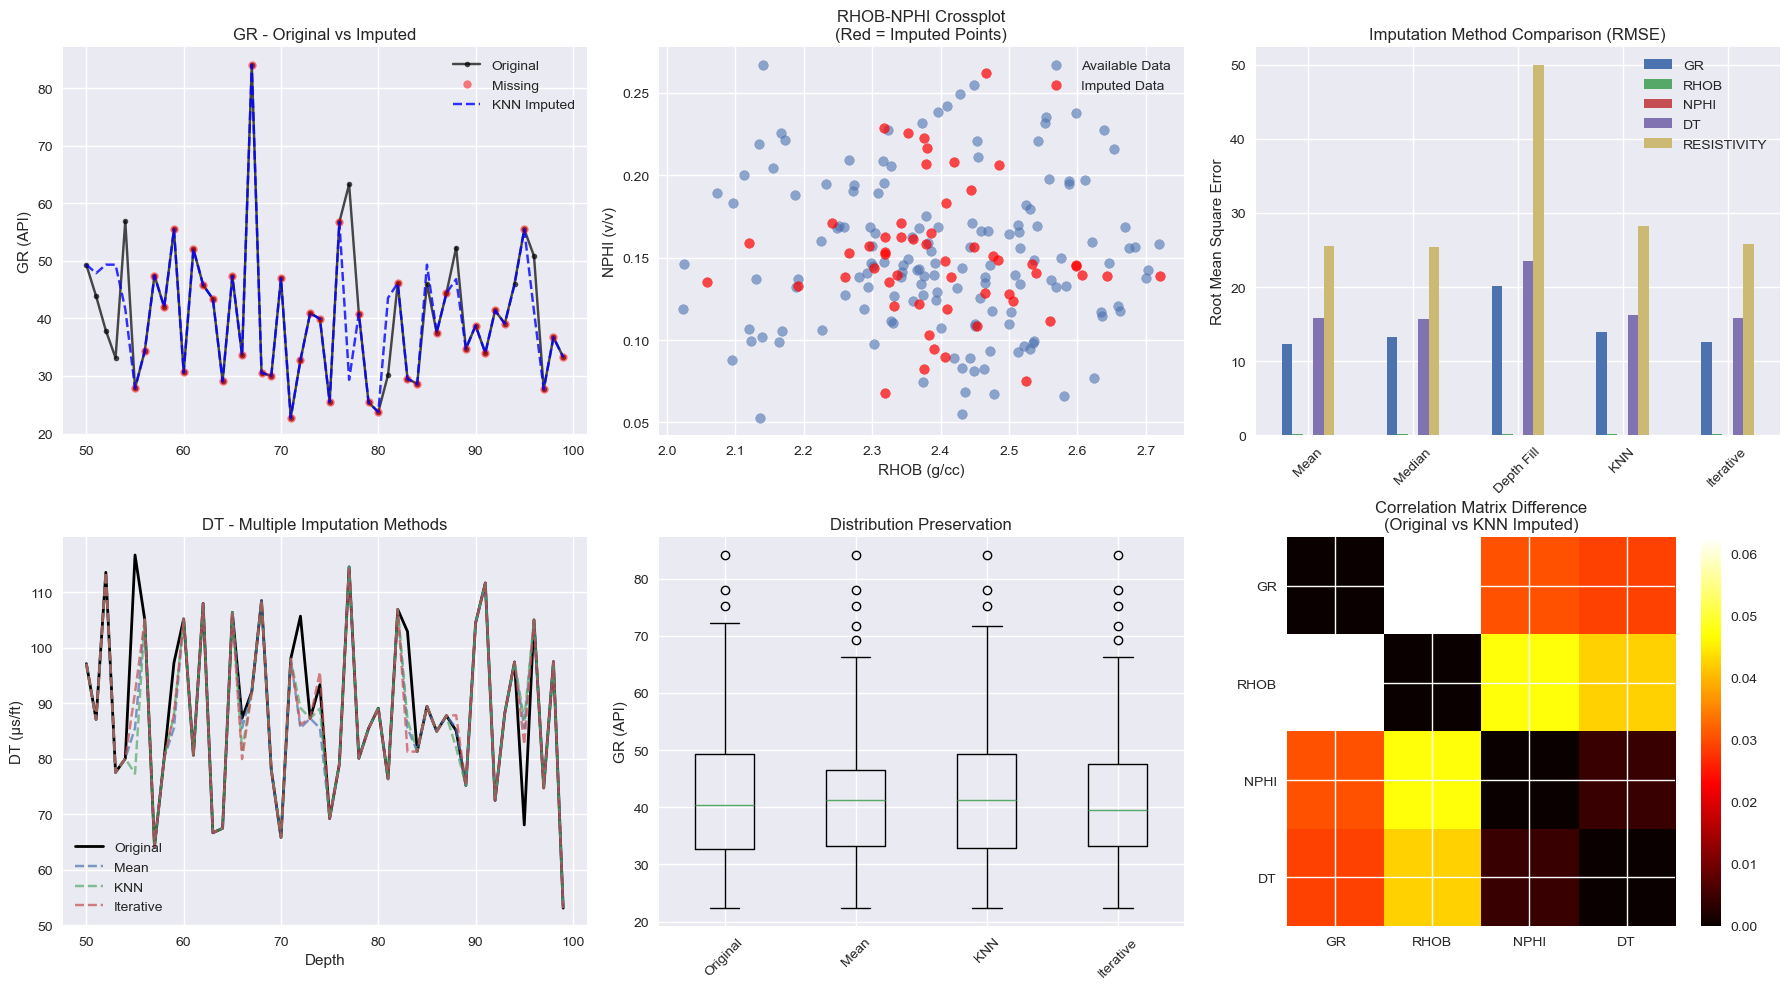

In [11]:
# Visualize imputation results
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Plot 1: Original vs Imputed GR
log_to_plot = 'GR'
sample_range = slice(50, 100)  # Look at a specific interval

axes[0,0].plot(df['DEPTH'][sample_range], df[log_to_plot][sample_range], 
               'ko-', label='Original', alpha=0.7, markersize=4)
axes[0,0].plot(df_missing['DEPTH'][sample_range], df_missing[log_to_plot][sample_range], 
               'ro', label='Missing', alpha=0.5, markersize=6)
axes[0,0].plot(df_knn['DEPTH'][sample_range], df_knn[log_to_plot][sample_range], 
               'b--', label='KNN Imputed', alpha=0.8)
axes[0,0].set_ylabel(f'{log_to_plot} (API)')
axes[0,0].set_title(f'{log_to_plot} - Original vs Imputed')
axes[0,0].legend()

# Plot 2: Crossplot RHOB vs NPHI
available_data = df_missing['RHOB'].notnull() & df_missing['NPHI'].notnull()
imputed_data = df_missing['RHOB'].isnull() | df_missing['NPHI'].isnull()

axes[0,1].scatter(df['RHOB'][available_data], df['NPHI'][available_data], 
                 alpha=0.6, label='Available Data')
axes[0,1].scatter(df_knn['RHOB'][imputed_data], df_knn['NPHI'][imputed_data], 
                 color='red', alpha=0.7, label='Imputed Data')
axes[0,1].set_xlabel('RHOB (g/cc)')
axes[0,1].set_ylabel('NPHI (v/v)')
axes[0,1].set_title('RHOB-NPHI Crossplot\n(Red = Imputed Points)')
axes[0,1].legend()

# Plot 3: RMSE comparison
eval_df.T.plot(kind='bar', ax=axes[0,2])
axes[0,2].set_title('Imputation Method Comparison (RMSE)')
axes[0,2].set_ylabel('Root Mean Square Error')
axes[0,2].tick_params(axis='x', rotation=45)

# Plot 4: Multiple methods comparison for one feature
feature = 'DT'
axes[1,0].plot(df['DEPTH'][sample_range], df[feature][sample_range], 
               'k-', label='Original', linewidth=2)
axes[1,0].plot(df_mean['DEPTH'][sample_range], df_mean[feature][sample_range], 
               '--', label='Mean', alpha=0.7)
axes[1,0].plot(df_knn['DEPTH'][sample_range], df_knn[feature][sample_range], 
               '--', label='KNN', alpha=0.7)
axes[1,0].plot(df_iterative['DEPTH'][sample_range], df_iterative[feature][sample_range], 
               '--', label='Iterative', alpha=0.7)
axes[1,0].set_ylabel(f'{feature} (μs/ft)')
axes[1,0].set_xlabel('Depth')
axes[1,0].set_title(f'{feature} - Multiple Imputation Methods')
axes[1,0].legend()

# Plot 5: Statistical distribution comparison
axes[1,1].boxplot([df['GR'].dropna(), df_mean['GR'], df_knn['GR'], df_iterative['GR']], 
                  labels=['Original', 'Mean', 'KNN', 'Iterative'])
axes[1,1].set_ylabel('GR (API)')
axes[1,1].set_title('Distribution Preservation')
axes[1,1].tick_params(axis='x', rotation=45)

# Plot 6: Correlation preservation
original_corr = df[['GR', 'RHOB', 'NPHI', 'DT']].corr().values
knn_corr = df_knn[['GR', 'RHOB', 'NPHI', 'DT']].corr().values
corr_diff = np.abs(original_corr - knn_corr)

im = axes[1,2].imshow(corr_diff, cmap='hot', interpolation='nearest')
axes[1,2].set_title('Correlation Matrix Difference\n(Original vs KNN Imputed)')
plt.colorbar(im, ax=axes[1,2])
axes[1,2].set_xticks(range(4))
axes[1,2].set_yticks(range(4))
axes[1,2].set_xticklabels(['GR', 'RHOB', 'NPHI', 'DT'])
axes[1,2].set_yticklabels(['GR', 'RHOB', 'NPHI', 'DT'])

plt.tight_layout()
plt.show()

#### 8. Practical Recommendations

In [12]:
print("\n" + "="*60)
print("PRACTICAL RECOMMENDATIONS FOR PETROPHYSICAL DATA IMPUTATION")
print("="*60)

recommendations = {
    "Simple Methods (Mean/Median)": {
        "When to use": "• Quick analysis\n• Minimal missing data (<5%)\n• Normal distributions",
        "Pros": "• Fast and simple\n• Easy to implement",
        "Cons": "• Ignores correlations\n• Can distort distributions"
    },
    "Depth-based Methods (Forward/Backward Fill)": {
        "When to use": "• Depth-series data\n• Local continuity expected\n• Tool failure gaps",
        "Pros": "• Preserves depth trends\n• Simple to implement",
        "Cons": "• Sensitive to data order\n• Can propagate errors"
    },
    "KNN Imputation": {
        "When to use": "• Correlated features\n• Moderate missing data (5-20%)\n• Similar patterns exist",
        "Pros": "• Uses feature relationships\n• Good for clustered data",
        "Cons": "• Computationally expensive\n• Sensitive to K choice"
    },
    "Iterative Imputation (MICE)": {
        "When to use": "• Complex relationships\n• Multiple correlated variables\n• Research-quality results",
        "Pros": "• Models complex relationships\n• Handles various data types",
        "Cons": "• Computationally intensive\n• Requires careful tuning"
    }
}

for method, info in recommendations.items():
    print(f"\n📊 {method}:")
    print(f"   When to use: {info['When to use']}")
    print(f"   Pros: {info['Pros']}")
    print(f"   Cons: {info['Cons']}")


PRACTICAL RECOMMENDATIONS FOR PETROPHYSICAL DATA IMPUTATION

📊 Simple Methods (Mean/Median):
   When to use: • Quick analysis
• Minimal missing data (<5%)
• Normal distributions
   Pros: • Fast and simple
• Easy to implement
   Cons: • Ignores correlations
• Can distort distributions

📊 Depth-based Methods (Forward/Backward Fill):
   When to use: • Depth-series data
• Local continuity expected
• Tool failure gaps
   Pros: • Preserves depth trends
• Simple to implement
   Cons: • Sensitive to data order
• Can propagate errors

📊 KNN Imputation:
   When to use: • Correlated features
• Moderate missing data (5-20%)
• Similar patterns exist
   Pros: • Uses feature relationships
• Good for clustered data
   Cons: • Computationally expensive
• Sensitive to K choice

📊 Iterative Imputation (MICE):
   When to use: • Complex relationships
• Multiple correlated variables
• Research-quality results
   Pros: • Models complex relationships
• Handles various data types
   Cons: • Computationally in

#### 9. Advanced: Domain-Aware Imputation

In [13]:
print("\n" + "="*50)
print("DOMAIN-AWARE IMPUTATION FOR PETROPHYSICS")
print("="*50)

print("""
Petrophysics-specific considerations:

1. **Lithology Constraints**: 
   - Sandstone: NPHI ~ 0.15-0.35, RHOB ~ 2.2-2.65 g/cc
   - Shale: GR > 80 API, NPHI ~ 0.25-0.45
   - Carbonate: DT ~ 40-50 μs/ft

2. **Physical Constraints**:
   - RHOB and NPHI must follow density-porosity relationships
   - Resistivity cannot be negative
   - DT has physical limits based on rock type

3. **Depth Consistency**:
   - Logs should vary smoothly with depth
   - Abrupt changes may indicate facies boundaries

4. **Multi-well Context**:
   - Use data from offset wells
   - Consider regional trends and depositional environment
""")

# Example: Physics-constrained imputation
def physics_constrained_imputation(df_missing):
    """Simple example of domain-aware imputation"""
    df_constrained = df_missing.copy()
    
    # Apply physical constraints during imputation
    for col in ['RHOB']:
        mask = df_missing[col].isnull()
        # Use KNN but constrain values
        temp_imputed = df_knn[col].copy()
        # Apply physical constraints (density bounds for sedimentary rocks)
        temp_imputed = np.clip(temp_imputed, 1.8, 3.0)
        df_constrained.loc[mask, col] = temp_imputed[mask]
    
    return df_constrained

df_constrained = physics_constrained_imputation(df_missing)
print("Domain-aware imputation applies petrophysical knowledge as constraints!")


DOMAIN-AWARE IMPUTATION FOR PETROPHYSICS

Petrophysics-specific considerations:

1. **Lithology Constraints**: 
   - Sandstone: NPHI ~ 0.15-0.35, RHOB ~ 2.2-2.65 g/cc
   - Shale: GR > 80 API, NPHI ~ 0.25-0.45
   - Carbonate: DT ~ 40-50 μs/ft

2. **Physical Constraints**:
   - RHOB and NPHI must follow density-porosity relationships
   - Resistivity cannot be negative
   - DT has physical limits based on rock type

3. **Depth Consistency**:
   - Logs should vary smoothly with depth
   - Abrupt changes may indicate facies boundaries

4. **Multi-well Context**:
   - Use data from offset wells
   - Consider regional trends and depositional environment

Domain-aware imputation applies petrophysical knowledge as constraints!


### Key Takeaways

In [14]:
print("\n" + "="*50)
print("KEY TAKEAWAYS")
print("="*50)

takeaways = [
    "1. **Always explore missing data patterns first** - understand why data is missing",
    "2. **Start simple** - use mean/median for quick analysis, advanced methods for final results", 
    "3. **Consider data relationships** - use correlation to guide method selection",
    "4. **Preserve distributions** - check if imputation changes statistical properties",
    "5. **Use domain knowledge** - apply petrophysical constraints where possible",
    "6. **Validate results** - compare multiple methods and use cross-validation",
    "7. **Document your approach** - note which method was used for which variable",
    "8. **Consider uncertainty** - advanced methods can provide confidence intervals"
]

for item in takeaways:
    print(f"• {item}")

print(f"\nRemember: The goal is not just to fill gaps, but to preserve the ")
print(f"underlying geological and petrophysical relationships in your data!")


KEY TAKEAWAYS
• 1. **Always explore missing data patterns first** - understand why data is missing
• 2. **Start simple** - use mean/median for quick analysis, advanced methods for final results
• 3. **Consider data relationships** - use correlation to guide method selection
• 4. **Preserve distributions** - check if imputation changes statistical properties
• 5. **Use domain knowledge** - apply petrophysical constraints where possible
• 6. **Validate results** - compare multiple methods and use cross-validation
• 7. **Document your approach** - note which method was used for which variable
• 8. **Consider uncertainty** - advanced methods can provide confidence intervals

Remember: The goal is not just to fill gaps, but to preserve the 
underlying geological and petrophysical relationships in your data!
